# Simulación Multiactivo
## Simulación de Procesos Financieros 

Ximena Muñoz 

11/11/26

## Objetivo

El objetivo de esta tarea es comparar el comportamiento de diferentes portafolios de inversión, considerando dos situaciones: cuando los activos son independientes y cuando existe correlación entre ellos.

Para esto utilizaremos simulaciones de Monte Carlo, rendimientos logarítmicos y descomposición de Cholesky. También analizaremos cómo cambia el riesgo dependiendo de los porcentajes de inversión.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


# Parte 1. Comparación de activos independientes y correlacionados

En esta primera parte vamos a trabajar con cuatro activos de diferentes sectores: Nvidia, Bimbo, Cemex y AstraZeneca.

Contamos con una inversión inicial de $100,000 MXN y queremos simular cuánto podría valer nuestro portafolio dentro de un año.

Primero realizaremos la simulación suponiendo independencia y después utilizaremos Cholesky para considerar la correlación entre los activos.

También simularemos el tipo de cambio USD/MXN, porque algunas de las acciones cotizan en dólares.


In [2]:
# Activos
tickers = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN"]

# Descargar datos históricos de 3 años
datos = yf.download( tickers, period="3y", auto_adjust=False, progress=False)

prices = datos["Close"][tickers].dropna()

prices

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Date,,,,
2023-11-13,48.619999,79.839996,12.120000,127.400002
2023-11-14,49.655998,82.690002,12.320000,128.460007
2023-11-15,48.888000,83.250000,12.190000,126.260002
2023-11-16,49.480000,83.709999,11.890000,127.599998
2023-11-17,49.298000,83.440002,12.070000,128.259995
...,...,...,...,...
2026-11-05,181.600006,69.599998,20.200001,186.850006
2026-11-06,186.639999,70.989998,20.150000,186.429993
2026-11-09,178.669998,68.500000,20.639999,189.389999


In [3]:
# Tipo de cambio USD/MXN
dolar = yf.download("USDMXN=X", period="3y", auto_adjust=False, progress=False)["Close"]

dolar = dolar.squeeze().dropna()

dolar

Date
2023-11-13    17.656401
2023-11-14    17.600100
2023-11-15    17.332500
2023-11-16    17.296169
2023-11-17    17.225800
                ...    
2026-11-05    18.607700
2026-11-06    18.780880
2026-11-09    18.637449
2026-11-10    18.533381
2026-11-11    18.618401
Name: USDMXN=X, Length: 778, dtype: float64


## 1. Rendimientos logarítmicos

Primero calculamos los rendimientos logarítmicos de los activos y del dólar utilizando los precios históricos.

Después calculamos el rendimiento promedio y la volatilidad anualizada de cada uno. Para esto consideramos 252 días hábiles por año.


In [4]:
# Rendimientos logarítmicos de los activos
rets = np.log(prices / prices.shift(1)).dropna()

rets

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Date,,,,
2023-11-14,0.021084,0.035074,0.016367,0.008286
2023-11-15,-0.015587,0.006749,-0.010608,-0.017274
2023-11-16,0.012037,0.005510,-0.024918,0.010557
2023-11-17,-0.003685,-0.003231,0.015025,0.005159
2023-11-21,0.013019,0.018288,-0.023471,0.002336
...,...,...,...,...
2026-11-05,-0.097161,0.038370,-0.011322,-0.011494
2026-11-06,0.027375,0.019774,-0.002478,-0.002250
2026-11-09,-0.043641,-0.035705,0.024027,0.015753


In [5]:
# Rendimientos logarítmicos del dólar
rets_dolar = np.log(dolar / dolar.shift(1)).dropna()

rets_dolar

Date
2023-11-14   -0.003194
2023-11-15   -0.015321
2023-11-16   -0.002098
2023-11-17   -0.004077
2023-11-20   -0.000355
                ...   
2026-11-05   -0.011212
2026-11-06    0.009264
2026-11-09   -0.007666
2026-11-10   -0.005599
2026-11-11    0.004577
Name: USDMXN=X, Length: 777, dtype: float64

In [6]:
# Rendimiento promedio anualizado
mu = rets.mean() * 252

# Volatilidad anualizada
sigma = rets.std() * np.sqrt(252)

# Rendimiento y volatilidad del dólar
mu_dolar = rets_dolar.mean() * 252
sigma_dolar = rets_dolar.std() * np.sqrt(252)

tabla_parametros = pd.DataFrame({
    "Rendimiento anual": mu,
    "Volatilidad anual": sigma
})

tabla_parametros.round(4)

,Rendimiento anual,Volatilidad anual
Ticker,,
NVDA,0.4414,0.4793
BIMBOA.MX,-0.0392,0.2995
CEMEXCPO.MX,0.1722,0.3297
AZN,0.1302,0.2527



## 2. Precios iniciales y escenarios de inversión

Utilizaremos los precios de cierre más recientes de los datos descargados.

Tenemos tres escenarios de inversión:

- **Escenario A:** 100% en Nvidia.
- **Escenario B:** 25% en cada activo.
- **Escenario C:** 10% en Nvidia, 20% en Bimbo, 30% en Cemex y 40% en AstraZeneca.

En todos los casos invertiremos $100,000 MXN.


In [7]:
# Precios iniciales
S0 = prices.iloc[-1]
tc0 = float(dolar.iloc[-1])

tabla_activos = pd.DataFrame({
    "i": [0, 1, 2, 3],
    "Ticker": tickers,
    "Moneda": ["USD", "MXN", "MXN", "USD"],
    "Precio inicial": [S0[ticker] for ticker in tickers]
})

tabla_activos

,i,Ticker,Moneda,Precio inicial
0,0,NVDA,USD,173.729996
1,1,BIMBOA.MX,MXN,71.309998
2,2,CEMEXCPO.MX,MXN,19.920000
3,3,AZN,USD,185.479996


In [8]:
# Parámetros
V0 = 100000
T = 1
M = 100000

# Esquemas de inversión
pesos = {
    "Escenario A": np.array([1, 0, 0, 0]),
    "Escenario B": np.array([0.25, 0.25, 0.25, 0.25]),
    "Escenario C": np.array([0.1, 0.2, 0.3, 0.4])
}

for nombre, w in pesos.items():
    print(nombre, ":", sum(w))

Escenario A : 1
Escenario B : 1.0
Escenario C : 1.0



## 3. Simulación independiente

Primero vamos a simular los precios futuros de los cuatro activos de manera independiente.

Utilizamos números aleatorios normales y la fórmula de simulación de precios que hemos trabajado en clase.

Cada activo tendrá 100,000 posibles resultados para dentro de un año.


In [9]:
np.random.seed(20)

ST_ind = np.zeros((M, len(tickers)))

cont = 0

for ticker in tickers:

    epsilon = np.random.normal(0, 1, M)

    ST_ind[:, cont] = S0[ticker] * np.exp(mu[ticker] * T+ sigma[ticker] * np.sqrt(T) * epsilon)

    cont += 1

ST_ind

array([[412.65770691, 111.29614061,  30.58945025, 235.59221578],
       [296.72691   ,  50.64576845,  23.52760507, 222.91104849],
       [320.63693633,  75.17196105,  35.79642274, 213.38422949],
       ...,
       [227.40147338,  90.84864644,  42.41491096, 235.26563818],
       [651.43409653,  61.05255706,  29.45656622, 213.19605991],
       [408.94511008, 162.10256421,  15.58426533, 176.12611433]])

In [10]:
# Simulación independiente del dólar
epsilon_dolar = np.random.normal(0, 1, M)

tcT_ind = tc0 * np.exp(
    mu_dolar * T
    + sigma_dolar * np.sqrt(T) * epsilon_dolar
)

tcT_ind

array([17.5187294 , 22.53010121, 17.54475363, ..., 19.14177051,
       16.27648571, 19.12618779])


## 4. Cantidad de acciones compradas

Ahora calculamos cuántas acciones podemos comprar con nuestros $100,000 MXN, dependiendo de los porcentajes de cada escenario.

Utilizamos la fórmula:

$$N_i=\frac{w_iV_0}{S_{0,i}}$$

Para las acciones que cotizan en dólares, primero convertimos la inversión a USD utilizando el tipo de cambio inicial.

En esta simulación permitimos cantidades fraccionarias de acciones para respetar los porcentajes de inversión.


In [11]:
# Cantidad de acciones por escenario
acciones = {}

for nombre, w in pesos.items():

    N = np.zeros(len(tickers))

    for i in range(len(tickers)):

        if tickers[i] == "NVDA" or tickers[i] == "AZN":
            N[i] = (w[i] * V0 / tc0) / S0[tickers[i]]

        else:
            N[i] = (w[i] * V0) / S0[tickers[i]]

    acciones[nombre] = N

tabla_acciones = pd.DataFrame({
    "Ticker": tickers,
    "Escenario A": acciones["Escenario A"],
    "Escenario B": acciones["Escenario B"],
    "Escenario C": acciones["Escenario C"]
})

tabla_acciones.round(4)

,Ticker,Escenario A,Escenario B,Escenario C
0,NVDA,30.916,7.7290,3.0916
1,BIMBOA.MX,0.000,350.5820,280.4656
2,CEMEXCPO.MX,0.000,1255.0201,1506.0241
3,AZN,0.000,7.2394,11.5830


In [12]:
# Valor final independiente
VT_ind = {}

for nombre in pesos:

    VT_ind[nombre] = (
        acciones[nombre][0] * ST_ind[:, 0] * tcT_ind
        + acciones[nombre][1] * ST_ind[:, 1]
        + acciones[nombre][2] * ST_ind[:, 2]
        + acciones[nombre][3] * ST_ind[:, 3] * tcT_ind
    )

VT_ind

{'Escenario A': array([223498.89801744, 206682.11539923, 173917.6447537 , ...,
        134573.08255498, 327803.77340694, 241811.11312452]),
 'Escenario B': array([163162.38525641, 135311.24689844, 141861.12518452, ...,
        151326.50268854, 165444.65130105, 161228.26463513]),
 'Escenario C': array([147439.2604409 , 128477.91879401, 135749.26736045, ...,
        154977.93509408, 134459.73629755, 132134.27304934])}


## 5. Simulación correlacionada con Cholesky

Ahora vamos a repetir la simulación, pero considerando que los activos pueden estar relacionados entre sí.

Primero calculamos la matriz de correlaciones de los rendimientos logarítmicos. Incluimos también el dólar, ya que su comportamiento puede estar relacionado con el de las acciones.

Después utilizamos la descomposición de Cholesky para generar números aleatorios correlacionados.

Usamos la matriz de correlaciones porque en la fórmula de precios incorporamos por separado la volatilidad de cada activo.


In [13]:
# Juntar rendimientos de activos y dólar
rendimientos = rets.copy()

rendimientos["USDMXN"] = rets_dolar

rendimientos = rendimientos.dropna()

# Orden de los factores
rendimientos = rendimientos[
    ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN", "USDMXN"]
]

# Matriz de correlaciones
R = rendimientos.corr()

R

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,USDMXN
Ticker,,,,,
NVDA,1.000000,0.079403,0.220494,0.013140,0.009335
BIMBOA.MX,0.079403,1.000000,0.184595,0.100215,0.045353
CEMEXCPO.MX,0.220494,0.184595,1.000000,0.102283,-0.021269
AZN,0.013140,0.100215,0.102283,1.000000,0.010329
USDMXN,0.009335,0.045353,-0.021269,0.010329,1.000000


In [14]:
# Descomposición de Cholesky
L = np.linalg.cholesky(R)

L

array([[ 1.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.07940278,  0.99684261,  0.        ,  0.        ,  0.        ],
       [ 0.22049399,  0.16761623,  0.96087835,  0.        ,  0.        ],
       [ 0.01313987,  0.0994857 ,  0.08607798,  0.99122173,  0.        ],
       [ 0.00933456,  0.04475349, -0.03208363,  0.00859132,  0.99840213]])

In [15]:
# Generar números aleatorios
np.random.seed(20)

epsilon = np.random.normal(0, 1, (5, M))

# Transformación con Cholesky
Z = L @ epsilon

Z

array([[ 0.88389311,  0.19586502,  0.35753652, ..., -0.35925167,
         1.83634503,  0.86503943],
       [ 1.68220142, -0.99300362,  0.33429144, ...,  0.90782942,
        -0.24073676,  2.93229572],
       [ 1.21406505, -0.1432405 ,  1.33649976, ...,  1.77888432,
         0.97803967, -0.54505054],
       [ 0.66692851,  0.11077696,  0.18230819, ...,  0.66305111,
         0.07828025, -0.52563585],
       [-0.65019711,  1.5354436 , -0.71892309, ...,  0.08111742,
        -1.39907691,  0.25925615]])

In [16]:
# Simulación correlacionada
ST_corr = np.zeros((M, len(tickers)))

cont = 0

for ticker in tickers:

    ST_corr[:, cont] = S0[ticker] * np.exp(
        mu[ticker] * T
        + sigma[ticker] * np.sqrt(T) * Z[cont, :]
    )

    cont += 1

ST_corr

array([[412.65770691, 113.48664104,  35.31258715, 250.05131907],
       [296.72691   ,  50.93092279,  22.57235477, 217.26932161],
       [320.63693633,  75.79184077,  36.7672349 , 221.23206574],
       ...,
       [227.40147338,  89.99582983,  42.54083838, 249.80645318],
       [651.43409653,  63.80117738,  32.66878979, 215.49256842],
       [408.94511008, 165.02288346,  19.771593  , 184.99499933]])

In [17]:
# Simulación correlacionada del dólar
tcT_corr = tc0 * np.exp(
    mu_dolar * T
    + sigma_dolar * np.sqrt(T) * Z[4, :]
)

tcT_corr

array([17.63553946, 22.42245642, 17.50287057, ..., 19.11109748,
       16.24253046, 19.4888429 ])

In [18]:
# Valor final correlacionado
VT_corr = {}

for nombre in pesos:

    VT_corr[nombre] = (
        acciones[nombre][0] * ST_corr[:, 0] * tcT_corr
        + acciones[nombre][1] * ST_corr[:, 1]
        + acciones[nombre][2] * ST_corr[:, 2]
        + acciones[nombre][3] * ST_corr[:, 3] * tcT_corr
    )

VT_corr

{'Escenario A': array([224989.12699794, 205694.62521704, 173502.46632584, ...,
        134357.44087325, 327119.92437388, 246396.13739771]),
 'Escenario B': array([172275.74377557, 132875.98606206, 144122.73536041, ...,
        153091.16436583, 170486.34056776, 170367.19587796]),
 'Escenario C': array([158588.15274552, 125277.31585372, 138831.18674457, ...,
        158042.05541374, 140348.13841235, 142459.9345983 ])}


## 6. Comparación de resultados

Ya tenemos las dos simulaciones: independiente y correlacionada.

Ahora compararemos el valor promedio, el riesgo y la probabilidad de pérdida de cada escenario.

Para medir el riesgo utilizamos la desviación estándar del valor final del portafolio. La probabilidad de pérdida representa el porcentaje de simulaciones donde terminamos con menos de los $100,000 iniciales.


In [19]:
# Tabla comparativa
tabla_corr = pd.DataFrame({
    "Escenario": list(pesos.keys()),

    "Promedio independiente": [
        VT_ind[nombre].mean() for nombre in pesos
    ],

    "Promedio correlacionado": [
        VT_corr[nombre].mean() for nombre in pesos
    ],

    "Riesgo independiente": [
        VT_ind[nombre].std() for nombre in pesos
    ],

    "Riesgo correlacionado": [
        VT_corr[nombre].std() for nombre in pesos
    ],

    "Prob. pérdida independiente (%)": [
        np.mean(VT_ind[nombre] < V0) * 100 for nombre in pesos
    ],

    "Prob. pérdida correlacionado (%)": [
        np.mean(VT_corr[nombre] < V0) * 100 for nombre in pesos
    ]
})

tabla_corr.round(2)

,Escenario,Promedio independiente,Promedio correlacionado,Riesgo independiente,Riesgo correlacionado,Prob. pérdida independiente (%),Prob. pérdida correlacionado (%)
0,Escenario A,179196.63,179287.60,94254.55,94525.46,17.35,17.42
1,Escenario B,131457.00,131508.48,28827.52,32043.02,10.86,14.22
2,Escenario C,123891.22,123939.55,22283.19,25161.70,13.20,16.72



## 7. Gráficas comparativas

Para observar las diferencias entre los dos métodos, realizamos un histograma para cada escenario.

En cada gráfica comparamos la distribución del valor final independiente contra el correlacionado.

La línea negra representa nuestra inversión inicial de $100,000 MXN. Los valores que quedan por debajo de esa línea representan pérdidas.


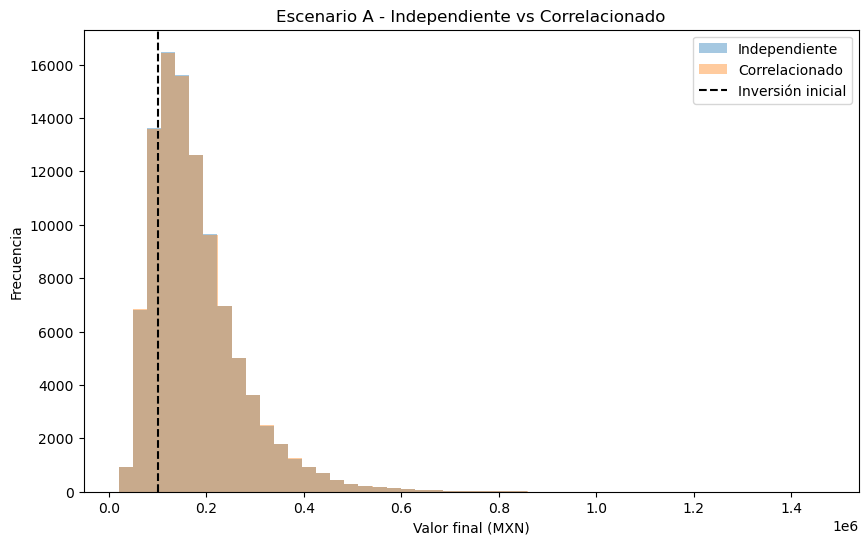

In [20]:
plt.figure(figsize=(10, 6))

plt.hist(VT_ind["Escenario A"], bins=50, alpha=0.4, label="Independiente")
plt.hist(VT_corr["Escenario A"], bins=50, alpha=0.4, label="Correlacionado")

plt.axvline(V0, color="black", linestyle="--", label="Inversión inicial")
plt.title("Escenario A - Independiente vs Correlacionado")
plt.xlabel("Valor final (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del escenario A

En este escenario invertimos el 100% en Nvidia. Aunque solamente tenemos una acción, también estamos expuestos al comportamiento del dólar.

Por eso puede existir una diferencia entre las simulaciones, ya que en el caso correlacionado consideramos la relación entre Nvidia y el tipo de cambio.

Al comparar las distribuciones podemos observar si esta relación cambia el riesgo de nuestra inversión.


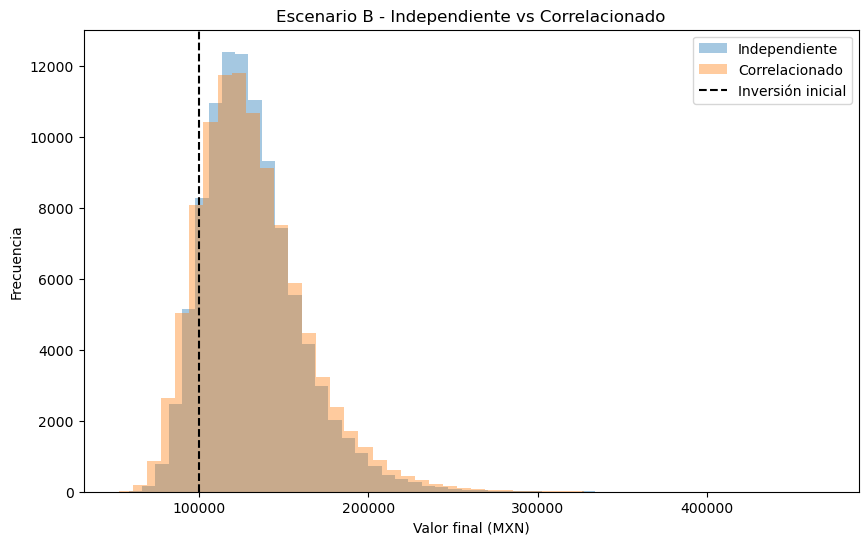

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(VT_ind["Escenario B"], bins=50, alpha=0.4, label="Independiente")
plt.hist(VT_corr["Escenario B"], bins=50, alpha=0.4, label="Correlacionado")

plt.axvline(V0, color="black", linestyle="--", label="Inversión inicial")
plt.title("Escenario B - Independiente vs Correlacionado")
plt.xlabel("Valor final (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del escenario B

En este escenario distribuimos nuestro dinero de manera equitativa entre los cuatro activos.

Aunque pertenecen a sectores diferentes, eso no significa que sean completamente independientes.

Al considerar la correlación podemos observar cómo cambian los posibles resultados y el riesgo del portafolio. Esto nos ayuda a entender que diversificar no elimina por completo el riesgo.


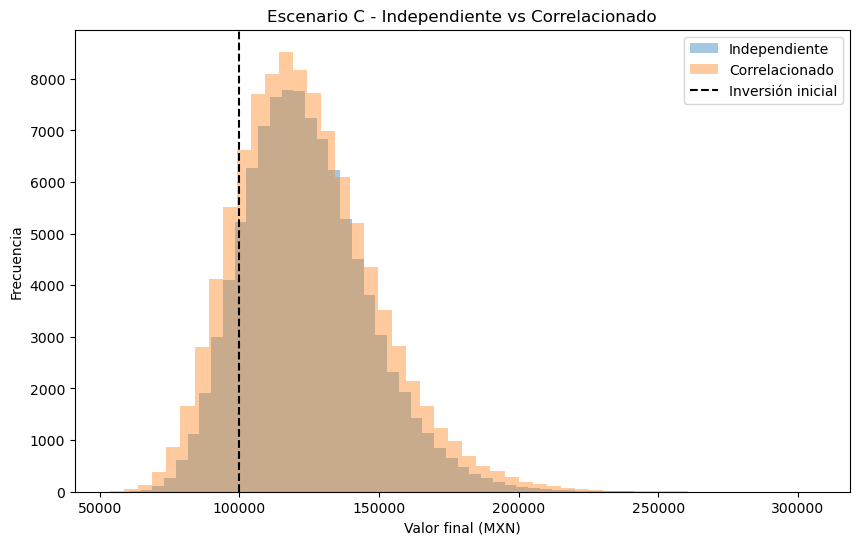

In [22]:
plt.figure(figsize=(10, 6))

plt.hist(VT_ind["Escenario C"], bins=50, alpha=0.4, label="Independiente")
plt.hist(VT_corr["Escenario C"], bins=50, alpha=0.4, label="Correlacionado")

plt.axvline(V0, color="black", linestyle="--", label="Inversión inicial")
plt.title("Escenario C - Independiente vs Correlacionado")
plt.xlabel("Valor final (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del escenario C

En este último escenario seguimos diversificando, pero ahora asignamos diferentes porcentajes a cada activo.

Esto nos permite observar cómo influye la distribución del dinero en los resultados.

Al comparar las dos simulaciones podemos analizar si las correlaciones entre los activos aumentan o disminuyen el riesgo de nuestro portafolio.


### Observación general 

Al comparar los resultados, podemos ver que en los tres escenarios el riesgo aumenta cuando consideramos la correlación. Por ejemplo, en el escenario B pasa de aproximadamente $28,822 a 32,037 MXN. Esto nos muestra que, aunque las empresas sean de diferentes sectores, sus rendimientos pueden estar relacionados y eso afecta el riesgo de nuestra inversión.


# Parte 2. Simulación de AAPL, MSFT y NVDA

En esta segunda parte trabajaremos con Apple, Microsoft y Nvidia.

Vamos a repetir el ejercicio de Cholesky, pero ahora aplicando una inversión inicial de $100,000 MXN.

Realizaremos simulaciones independientes y correlacionadas para comparar el comportamiento de tres portafolios con diferentes porcentajes de inversión.

En este ejercicio utilizaremos un tipo de cambio fijo para convertir los resultados a pesos mexicanos, como una simplificación del modelo.


In [23]:
# Activos de la parte 2
tickers2 = ["AAPL", "MSFT", "NVDA"]

# Descargar datos históricos
prices2 = yf.download(
    tickers=tickers2,
    start="2023-11-01",
    end="2026-11-01",
    auto_adjust=False
)["Close"]

# Ordenar las columnas
prices2 = prices2[tickers2].dropna()

prices2

[*********************100%***********************]  3 of 3 completed


Ticker,AAPL,MSFT,NVDA
Date,,,
2023-11-01,173.970001,346.070007,42.325001
2023-11-02,177.570007,348.320007,43.506001
2023-11-03,176.649994,352.799988,45.005001
2023-11-06,179.229996,356.529999,45.750999
2023-11-07,181.820007,360.529999,45.955002
...,...,...,...
2026-10-26,343.910004,532.599976,216.000000
2026-10-27,347.100006,531.330017,217.940002
2026-10-28,343.829987,531.010010,215.380005



## 1. Rendimientos logarítmicos y correlaciones

Primero calculamos los rendimientos logarítmicos de las tres acciones.

Después obtenemos la matriz de correlaciones, que nos permite observar qué tan relacionados están sus rendimientos.

Si dos activos tienen correlación positiva, significa que tienden a moverse en la misma dirección. Si es negativa, tienden a moverse en direcciones contrarias.


In [24]:
# Rendimientos logarítmicos
rets2 = np.log(prices2 / prices2.shift(1)).dropna()

rets2

Ticker,AAPL,MSFT,NVDA
Date,,,
2023-11-02,0.020482,0.006481,0.027521
2023-11-03,-0.005195,0.012780,0.033875
2023-11-06,0.014500,0.010517,0.016440
2023-11-07,0.014347,0.011157,0.004449
2023-11-08,0.005868,0.007379,0.013380
...,...,...,...
2026-10-26,-0.011046,0.015306,0.023610
2026-10-27,0.009233,-0.002387,0.008941
2026-10-28,-0.009466,-0.000602,-0.011816


In [25]:
# Matriz de correlaciones
Sigma2 = rets2.corr()

Sigma2

Ticker,AAPL,MSFT,NVDA
Ticker,,,
AAPL,1.000000,0.333937,0.283579
MSFT,0.333937,1.000000,0.421815
NVDA,0.283579,0.421815,1.000000



## 2. Descomposición de Cholesky

Utilizamos la descomposición de Cholesky para transformar números aleatorios independientes en números aleatorios correlacionados.

En este caso trabajamos con la matriz de correlaciones, ya que después incorporaremos la volatilidad de cada acción en la fórmula de simulación de precios.


In [26]:
# Descomposición de Cholesky
L2 = np.linalg.cholesky(Sigma2)

L2

array([[1.        , 0.        , 0.        ],
       [0.33393714, 0.94259535, 0.        ],
       [0.28357918, 0.34703914, 0.89395005]])

In [27]:
# Parámetros
M2 = 10000
T2 = 1

np.random.seed(20)

# Números aleatorios independientes
epsilon2 = np.random.normal(0, 1, (3, M2))

# Números aleatorios correlacionados
Z2 = L2 @ epsilon2

Z2.T

array([[ 0.88389311,  0.02499975,  0.19057976],
       [ 0.19586502, -0.00588139, -1.55502095],
       [ 0.35753652,  0.27670217,  0.63853447],
       ...,
       [-0.83150859, -1.00791072, -1.50989848],
       [-1.39333982,  0.46377204,  0.62377745],
       [-1.06350348, -0.29432607,  0.38757094]])


## 3. Simulación de precios futuros

Ahora simulamos los precios futuros de Apple, Microsoft y Nvidia para dentro de un año.

Utilizamos los mismos rendimientos promedio y volatilidades en ambas simulaciones.

La única diferencia es que en la simulación independiente utilizamos los números aleatorios originales, mientras que en la correlacionada utilizamos los valores transformados mediante Cholesky.


In [28]:
# Simulación de precios independientes
ST_ind2 = np.zeros((M2, len(tickers2)))

cont = 0

for i in tickers2:

    S0 = prices2.iloc[-1][i]
    mu = rets2[i].mean() * 252
    vol = rets2[i].std() * np.sqrt(252)

    ST_ind2[:, cont] = S0 * np.exp(
        mu * T2
        + vol * np.sqrt(T2) * epsilon2[cont, :]
    )

    cont += 1

ST_ind2

array([[548.73461125, 556.17089442, 354.44690458],
       [456.73118201, 587.43018449, 152.15211157],
       [476.85771148, 625.53692964, 445.69615082],
       ...,
       [347.25533908, 490.08405964, 205.71245442],
       [298.92757503, 773.40736863, 494.01293099],
       [326.41827771, 609.15948533, 491.42699624]])

In [29]:
# Simulación de precios correlacionados
ST_corr2 = np.zeros((M2, len(tickers2)))

cont = 0

for i in tickers2:

    S0 = prices2.iloc[-1][i]
    mu = rets2[i].mean() * 252
    vol = rets2[i].std() * np.sqrt(252)

    ST_corr2[:, cont] = S0 * np.exp(
        mu * T2
        + vol * np.sqrt(T2) * Z2[cont, :]
    )

    cont += 1

ST_corr2

array([[548.73461125, 602.95188859, 379.46951299],
       [456.73118201, 598.14545781, 168.34736027],
       [476.85771148, 643.5958305 , 467.47235084],
       ...,
       [347.25533908, 461.34159954, 171.92155771],
       [298.92757503, 675.5679177 , 464.27144531],
       [326.41827771, 555.06097441, 415.91985183]])


## 4. Esquemas de inversión

Ahora aplicamos una inversión inicial de $100,000 MXN a los tres esquemas solicitados:

- **Esquema 1:** 100% en Apple.
- **Esquema 2:** 33% en Apple, 33% en Microsoft y 34% en Nvidia.
- **Esquema 3:** 20% en Apple, 20% en Microsoft y 60% en Nvidia.

Primero convertimos nuestro capital a dólares y después calculamos la cantidad de acciones que podemos comprar.

Utilizaremos la misma cantidad de acciones para comparar las dos simulaciones.


In [30]:
# Esquemas de inversión
pesos2 = {
    "Esquema 1": np.array([1, 0, 0]),
    "Esquema 2": np.array([0.33, 0.33, 0.34]),
    "Esquema 3": np.array([0.2, 0.2, 0.6])
}

for nombre, w in pesos2.items():
    print(nombre, ":", sum(w))

Esquema 1 : 1
Esquema 2 : 1.0
Esquema 3 : 1.0


In [31]:
# Descargar tipo de cambio
tipo_cambio2 = yf.download("USDMXN=X",start="2026-10-30", end="2026-11-01",auto_adjust=False)["Close"]

tc2 = tipo_cambio2.iloc[-1].item()

tc2

[*********************100%***********************]  1 of 1 completed


18.852100372314453

In [32]:
# Capital inicial
V0_MXN2 = 100000

# Conversión a dólares
V0_USD2 = V0_MXN2 / tc2

V0_USD2

5304.448736484374

In [33]:
# Precios iniciales
S02 = prices2.iloc[-1].values

# Cantidad de acciones compradas
acciones2 = {}

for nombre, w in pesos2.items():

    acciones2[nombre] = (V0_USD2 * w) / S02

tabla_acciones2 = pd.DataFrame({
    "Ticker": tickers2,
    "Esquema 1": acciones2["Esquema 1"],
    "Esquema 2": acciones2["Esquema 2"],
    "Esquema 3": acciones2["Esquema 3"]
})

tabla_acciones2.round(4)

,Ticker,Esquema 1,Esquema 2,Esquema 3
0,AAPL,15.3917,5.0793,3.0783
1,MSFT,0.0000,3.3540,2.0327
2,NVDA,0.0000,8.8131,15.5525



## 5. Valor final de los portafolios

Con las cantidades de acciones que compramos, calculamos el valor final de cada portafolio.

Para esto multiplicamos las acciones por sus precios futuros simulados y sumamos los resultados.

Después convertimos los valores finales a pesos mexicanos utilizando el tipo de cambio fijo.

Finalmente calculamos las ganancias o pérdidas respecto a nuestra inversión inicial de $100,000 MXN.


In [34]:
# Valor futuro de los portafolios en USD
VT_ind2 = {}
VT_corr2 = {}

for nombre in pesos2:

    VT_ind2[nombre] = ST_ind2 @ acciones2[nombre]
    VT_corr2[nombre] = ST_corr2 @ acciones2[nombre]

# Convertir los valores a pesos mexicanos
for nombre in pesos2:

    VT_ind2[nombre] = VT_ind2[nombre] * tc2
    VT_corr2[nombre] = VT_corr2[nombre] * tc2

VT_ind2

{'Esquema 1': array([159224.27051444, 132527.97943756, 138368.0192463 , ...,
        100761.78340707,  86738.69680505,  94715.57121794]),
 'Esquema 2': array([146600.03536352, 106156.40751495, 159264.08293848, ...,
         98417.24192806, 159603.76229338, 151421.21164143]),
 'Esquema 3': array([157080.81628499,  93627.04798746, 182321.80628293, ...,
         99247.20415262, 191828.82734501, 186371.90395282])}

In [35]:
# Ganancias y pérdidas
PnL_ind2 = {}
PnL_corr2 = {}

for nombre in pesos2:

    PnL_ind2[nombre] = VT_ind2[nombre] - V0_MXN2
    PnL_corr2[nombre] = VT_corr2[nombre] - V0_MXN2

PnL_ind2

{'Esquema 1': array([ 59224.27051444,  32527.97943756,  38368.0192463 , ...,
           761.78340707, -13261.30319495,  -5284.42878206]),
 'Esquema 2': array([46600.03536352,  6156.40751495, 59264.08293848, ...,
        -1582.75807194, 59603.76229338, 51421.21164143]),
 'Esquema 3': array([57080.81628499, -6372.95201254, 82321.80628293, ...,
         -752.79584738, 91828.82734501, 86371.90395282])}


## 6. Tabla comparativa de resultados

En esta tabla comparamos las ganancias y pérdidas de los tres esquemas.

Calculamos el promedio, el mínimo y el máximo de cada simulación.

También analizamos el riesgo mediante la desviación estándar y calculamos la probabilidad de pérdida, que representa el porcentaje de simulaciones donde terminamos con menos dinero del que invertimos.


In [36]:
# Resumen de ganancias y pérdidas
tabla_resultados2 = pd.DataFrame({
    "Esquema": list(pesos2.keys()),

    "Promedio independiente": [
        PnL_ind2[nombre].mean() for nombre in pesos2
    ],

    "Mínimo independiente": [
        PnL_ind2[nombre].min() for nombre in pesos2
    ],

    "Máximo independiente": [
        PnL_ind2[nombre].max() for nombre in pesos2
    ],

    "Promedio correlacionado": [
        PnL_corr2[nombre].mean() for nombre in pesos2
    ],

    "Mínimo correlacionado": [
        PnL_corr2[nombre].min() for nombre in pesos2
    ],

    "Máximo correlacionado": [
        PnL_corr2[nombre].max() for nombre in pesos2
    ]
})

tabla_resultados2.round(2)

,Esquema,Promedio independiente,Mínimo independiente,Máximo independiente,Promedio correlacionado,Mínimo correlacionado,Máximo correlacionado
0,Esquema 1,30897.34,-54398.70,269010.91,30897.34,-54398.70,269010.91
1,Esquema 2,46563.26,-34692.36,286205.53,46689.68,-44407.71,352832.05
2,Esquema 3,63360.51,-40787.42,466526.69,63524.29,-52991.85,560999.53


In [37]:
# Comparación de riesgo y probabilidad de pérdida
tabla_riesgo2 = pd.DataFrame({
    "Esquema": list(pesos2.keys()),

    "Riesgo independiente": [
        PnL_ind2[nombre].std() for nombre in pesos2
    ],

    "Riesgo correlacionado": [
        PnL_corr2[nombre].std() for nombre in pesos2
    ],

    "Prob. pérdida independiente (%)": [
        np.mean(PnL_ind2[nombre] < 0) * 100 for nombre in pesos2
    ],

    "Prob. pérdida correlacionado (%)": [
        np.mean(PnL_corr2[nombre] < 0) * 100 for nombre in pesos2
    ]
})

tabla_riesgo2.round(2)

,Esquema,Riesgo independiente,Riesgo correlacionado,Prob. pérdida independiente (%),Prob. pérdida correlacionado (%)
0,Esquema 1,35557.12,35557.12,18.94,18.94
1,Esquema 2,35824.86,42936.64,5.22,10.52
2,Esquema 3,57337.19,62233.93,7.90,11.18



## 7. Gráficas comparativas

Finalmente realizamos tres histogramas para comparar las distribuciones de ganancias y pérdidas de cada esquema.

En cada gráfica mostramos los resultados independientes y correlacionados.

La línea negra representa el punto donde no tenemos ni ganancias ni pérdidas. Los valores negativos representan pérdidas y los positivos representan ganancias.


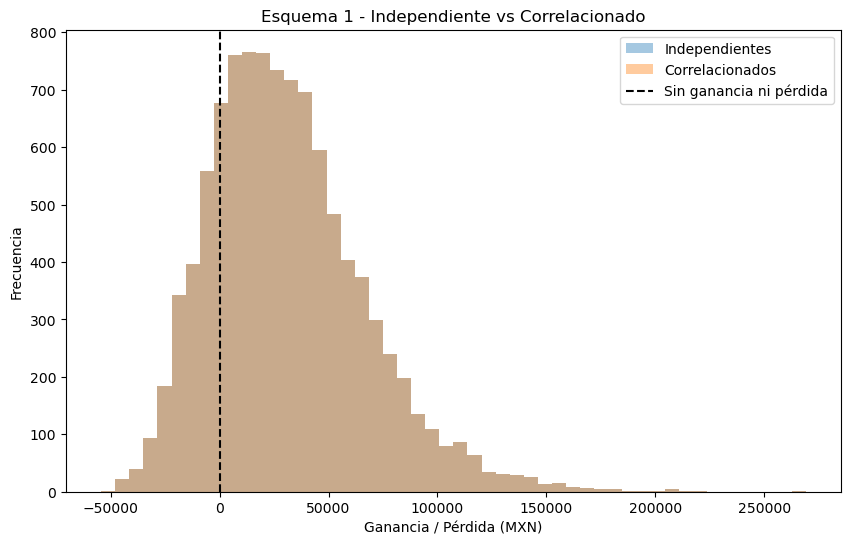

In [38]:
# Esquema 1
resultados = {
    "Independientes": {"PnL": PnL_ind2["Esquema 1"]},
    "Correlacionados": {"PnL": PnL_corr2["Esquema 1"]}
}

plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--", label="Sin ganancia ni pérdida")
plt.title("Esquema 1 - Independiente vs Correlacionado")
plt.xlabel("Ganancia / Pérdida (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del esquema 1

En este esquema invertimos todo nuestro dinero en Apple.

Como solamente tenemos un activo y utilizamos un tipo de cambio fijo, las dos simulaciones presentan la misma distribución.

Esto sucede porque la correlación con Microsoft y Nvidia no afecta directamente a un portafolio que solamente contiene acciones de Apple.


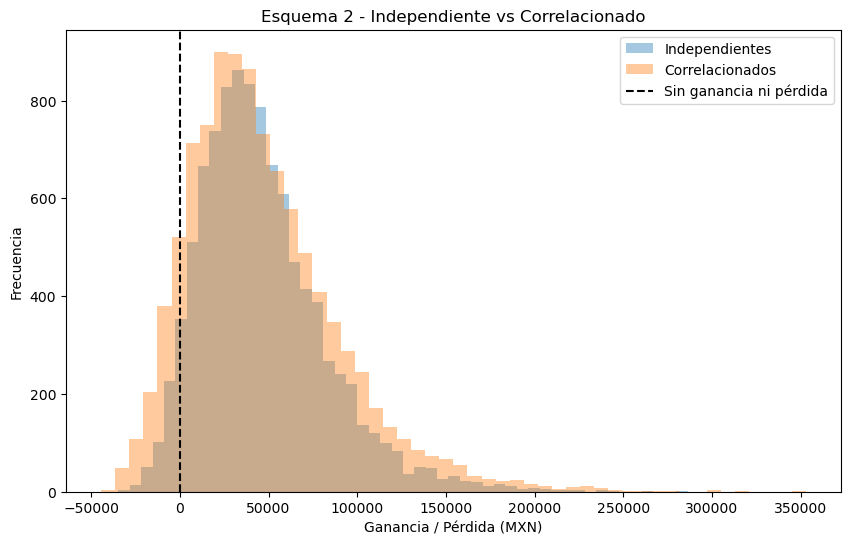

In [39]:
# Esquema 2
resultados = {
    "Independientes": {"PnL": PnL_ind2["Esquema 2"]},
    "Correlacionados": {"PnL": PnL_corr2["Esquema 2"]}
}

plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--", label="Sin ganancia ni pérdida")
plt.title("Esquema 2 - Independiente vs Correlacionado")
plt.xlabel("Ganancia / Pérdida (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del esquema 2

En este esquema distribuimos nuestro dinero casi de manera equitativa entre Apple, Microsoft y Nvidia.

Al incluir tres activos, la correlación entre ellos puede influir en el riesgo total del portafolio.

Por eso es importante comparar la dispersión de los histogramas y la probabilidad de pérdida, no solamente las ganancias promedio.


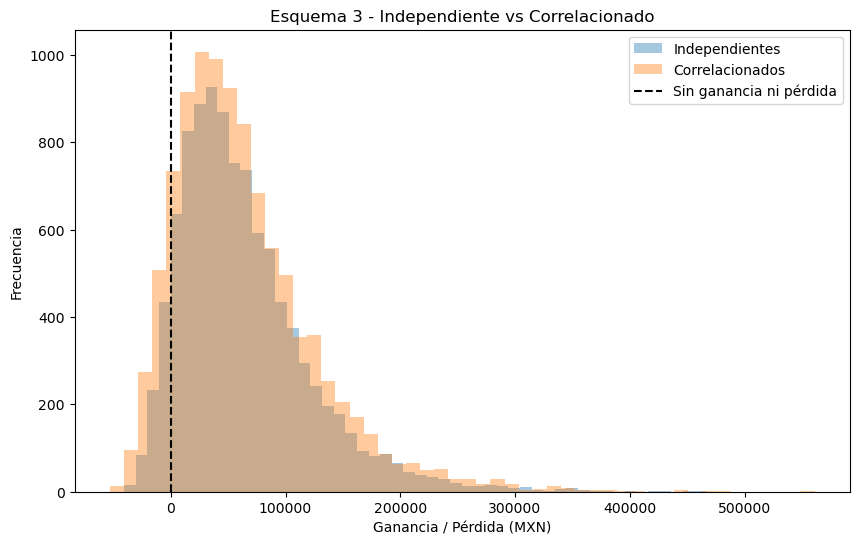

In [40]:
# Esquema 3
resultados = {
    "Independientes": {"PnL": PnL_ind2["Esquema 3"]},
    "Correlacionados": {"PnL": PnL_corr2["Esquema 3"]}
}

plt.figure(figsize=(10, 6))

for nombre, datos in resultados.items():
    plt.hist(datos["PnL"], bins=50, alpha=0.4, label=nombre)

plt.axvline(0, color="black", linestyle="--", label="Sin ganancia ni pérdida")
plt.title("Esquema 3 - Independiente vs Correlacionado")
plt.xlabel("Ganancia / Pérdida (MXN)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


### Observación del esquema 3

En este esquema invertimos el 60% del capital en Nvidia y el resto en Apple y Microsoft.

Esto significa que nuestro portafolio depende más del comportamiento de Nvidia.

Al considerar la correlación podemos observar cómo cambia el riesgo cuando varios activos se mueven de manera relacionada.

También podemos comparar este esquema con el anterior para ver cómo influyen los porcentajes de inversión en los resultados.


### Observación general

En esta segunda parte vimos que el esquema 1 tiene los mismos resultados en las dos simulaciones porque solamente invertimos en Apple. En cambio, en los esquemas 2 y 3 el riesgo aumenta cuando consideramos la correlación. Por ejemplo, en el esquema 2 la probabilidad de perder dinero pasa de 5.22% a 10.52%. Esto nos muestra que es importante tomar en cuenta cómo se relacionan las acciones, no solamente cuánto esperamos ganar.


# Conclusión

Con esta actividad pudimos observar cómo cambia el comportamiento de un portafolio cuando consideramos que los activos son independientes o que existe correlación entre ellos.

En la primera parte trabajamos con empresas de diferentes sectores y vimos que diversificar nuestras inversiones no significa que los activos sean completamente independientes. Aunque pertenezcan a sectores distintos, sus rendimientos pueden estar relacionados. También consideramos el comportamiento del dólar, que puede afectar el valor de nuestras inversiones en pesos.

En la segunda parte utilizamos Apple, Microsoft y Nvidia. Al comparar los tres esquemas, pudimos observar que los porcentajes que asignamos a cada acción también influyen en el riesgo del portafolio.

Algo importante que aprendimos es que no basta con buscar la mayor ganancia promedio, también debemos considerar qué tanto pueden variar los resultados y qué probabilidad tenemos de perder dinero.

En general, esta actividad nos ayudó a entender mejor la importancia de la diversificación, la correlación y la simulación de diferentes escenarios antes de tomar decisiones de inversión.
